In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import sys
import os

# --- Configuration ---
DATASET_ROOT = Path("../extracted_one_shots")  # <-- update this
MEAN_LOG_F0_DIR = DATASET_ROOT / "prosodic" / "mean_log_f0"
STD_LOG_F0_DIR = DATASET_ROOT / "prosodic" / "std_log_f0"

In [11]:
records = []
for path in sorted(MEAN_LOG_F0_DIR.glob("*.txt")):
    mean_val = float(path.read_text(encoding="utf-8").strip())
    std_path = STD_LOG_F0_DIR / path.name
    std_val = float(std_path.read_text(encoding="utf-8").strip()) if std_path.exists() else np.nan
    records.append({
        "file": path.stem,
        "mean_log_f0": mean_val,
        "std_log_f0": std_val,
        "mean_f0_hz": np.exp(mean_val),
    })

df = pd.DataFrame(records)
assert len(df) > 0, f"No .txt files found in {MEAN_LOG_F0_DIR}"

x = df["mean_log_f0"].to_numpy()
hz = df["mean_f0_hz"].to_numpy()
cents_span = (1200.0 / np.log(2)) * (x.max() - x.min())

print(f"Loaded {len(df)} files")
print(f"F0 range: {hz.min():.1f} Hz – {hz.max():.1f} Hz  ({cents_span:.0f} cents / {cents_span/100:.1f} semitones)")
print(df[["mean_log_f0", "mean_f0_hz", "std_log_f0"]].describe().round(4))

Loaded 4342 files
F0 range: 50.0 Hz – 366.8 Hz  (3450 cents / 34.5 semitones)
       mean_log_f0  mean_f0_hz  std_log_f0
count    4342.0000   4342.0000   4342.0000
mean        5.2565    212.8176      0.0074
std         0.5063     79.7825      0.0187
min         3.9120     50.0000      0.0000
25%         5.0166    150.9033      0.0026
50%         5.5929    268.5145      0.0043
75%         5.6072    272.3890      0.0083
max         5.9048    366.8016      0.4115


Suggested bin counts (statistical rules):
  Freedman-Diaconis : 28
  Scott's rule      : 19
  Sturges' rule     : 14
  Square-root rule  : 66


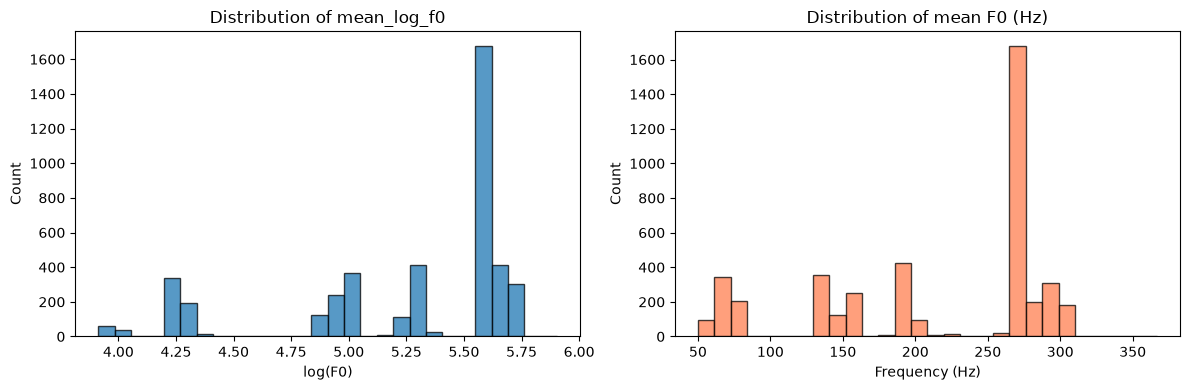

In [12]:
n = len(x)
iqr = np.percentile(x, 75) - np.percentile(x, 25)
data_range = x.max() - x.min()

# Classic histogram rules
k_fd = int(np.ceil(data_range / (2 * iqr * n ** (-1/3)))) if iqr > 0 else 1
k_scott = int(np.ceil(data_range / (3.5 * np.std(x) * n ** (-1/3)))) if np.std(x) > 0 else 1
k_sturges = int(np.ceil(np.log2(n) + 1))
k_sqrt = int(np.ceil(np.sqrt(n)))

print("Suggested bin counts (statistical rules):")
print(f"  Freedman-Diaconis : {k_fd}")
print(f"  Scott's rule      : {k_scott}")
print(f"  Sturges' rule     : {k_sturges}")
print(f"  Square-root rule  : {k_sqrt}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(x, bins=max(k_fd, 10), edgecolor="black", alpha=0.75)
axes[0].set_title("Distribution of mean_log_f0")
axes[0].set_xlabel("log(F0)")
axes[0].set_ylabel("Count")

axes[1].hist(hz, bins=max(k_fd, 10), edgecolor="black", alpha=0.75, color="coral")
axes[1].set_title("Distribution of mean F0 (Hz)")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

Best K by GMM BIC (lower is better)       : 15
Best K by Silhouette (higher is better)   : 4


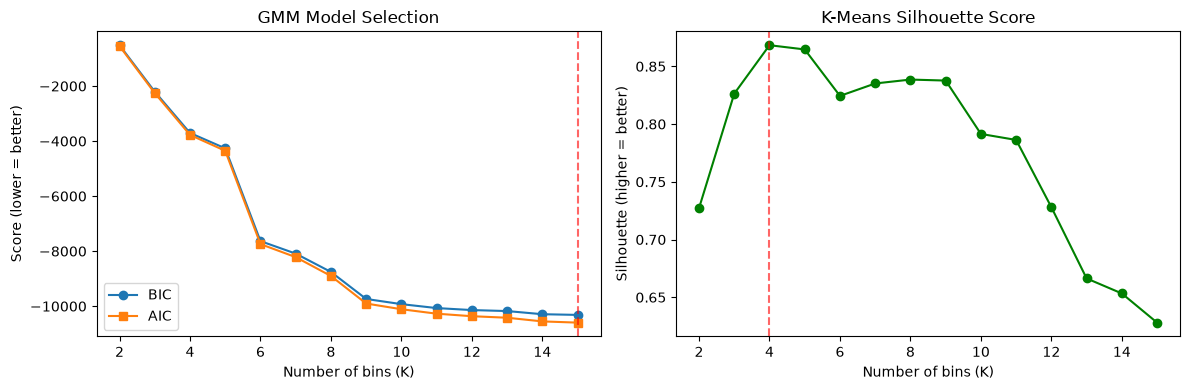

In [13]:
X = x.reshape(-1, 1)
max_k = min(15, n - 1)
ks = list(range(2, max_k + 1))

bics, aics, sils = [], [], []
for k in ks:
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=5).fit(X)
    bics.append(gmm.bic(X))
    aics.append(gmm.aic(X))

    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    sils.append(silhouette_score(X, km.labels_))

best_k_bic = ks[int(np.argmin(bics))]
best_k_sil = ks[int(np.argmax(sils))]
print(f"Best K by GMM BIC (lower is better)       : {best_k_bic}")
print(f"Best K by Silhouette (higher is better)   : {best_k_sil}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, bics, marker="o", label="BIC")
axes[0].plot(ks, aics, marker="s", label="AIC")
axes[0].axvline(best_k_bic, color="red", linestyle="--", alpha=0.6)
axes[0].set_title("GMM Model Selection")
axes[0].set_xlabel("Number of bins (K)")
axes[0].set_ylabel("Score (lower = better)")
axes[0].legend()

axes[1].plot(ks, sils, marker="o", color="green")
axes[1].axvline(best_k_sil, color="red", linestyle="--", alpha=0.6)
axes[1].set_title("K-Means Silhouette Score")
axes[1].set_xlabel("Number of bins (K)")
axes[1].set_ylabel("Silhouette (higher = better)")

plt.tight_layout()
plt.show()

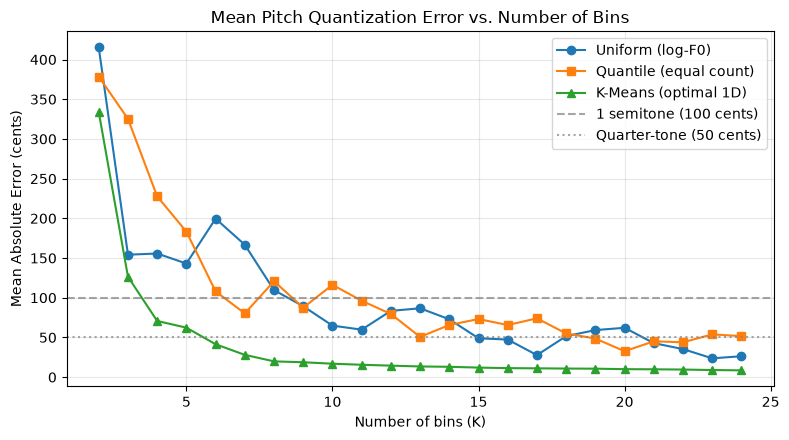

In [14]:
def quantization_error_cents(values: np.ndarray, k: int, method: str) -> float:
    if method == "uniform":
        edges = np.linspace(values.min(), values.max(), k + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        idx = np.clip(np.digitize(values, edges[1:-1]), 0, k - 1)
        recon = centers[idx]
    elif method == "quantile":
        edges = np.quantile(values, np.linspace(0, 1, k + 1))
        idx = np.clip(np.digitize(values, edges[1:-1]), 0, k - 1)
        centers = np.array([values[idx == i].mean() if np.any(idx == i) else 0.5 * (edges[i] + edges[i+1]) for i in range(k)])
        recon = centers[idx]
    elif method == "kmeans":
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(values.reshape(-1, 1))
        recon = km.cluster_centers_[km.labels_].ravel()
    else:
        raise ValueError(method)

    # Convert log-Hz error to cents: 1200 / ln(2) * |Δ log(f)|
    err_cents = (1200.0 / np.log(2)) * np.abs(values - recon)
    return float(np.mean(err_cents))

k_range = list(range(2, min(25, n)))
err_uniform = [quantization_error_cents(x, k, "uniform") for k in k_range]
err_quantile = [quantization_error_cents(x, k, "quantile") for k in k_range]
err_kmeans = [quantization_error_cents(x, k, "kmeans") for k in k_range]

plt.figure(figsize=(8, 4.5))
plt.plot(k_range, err_uniform, marker="o", label="Uniform (log-F0)")
plt.plot(k_range, err_quantile, marker="s", label="Quantile (equal count)")
plt.plot(k_range, err_kmeans, marker="^", label="K-Means (optimal 1D)")
plt.axhline(100, color="gray", linestyle="--", alpha=0.7, label="1 semitone (100 cents)")
plt.axhline(50, color="gray", linestyle=":", alpha=0.7, label="Quarter-tone (50 cents)")
plt.title("Mean Pitch Quantization Error vs. Number of Bins")
plt.xlabel("Number of bins (K)")
plt.ylabel("Mean Absolute Error (cents)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
CHOSEN_K = 25  # <-- change this after inspecting the plots above

edges = np.quantile(x, np.linspace(0, 1, CHOSEN_K + 1))  # or np.linspace(x.min(), x.max(), CHOSEN_K + 1)
bin_ids = np.clip(np.digitize(x, edges[1:-1]), 0, CHOSEN_K - 1)

summary = []
for i in range(CHOSEN_K):
    mask = bin_ids == i
    summary.append({
        "bin": i,
        "count": int(mask.sum()),
        "low_hz": round(float(np.exp(edges[i])), 1),
        "high_hz": round(float(np.exp(edges[i + 1])), 1),
        "low_log_f0": round(float(edges[i]), 4),
        "high_log_f0": round(float(edges[i + 1]), 4),
    })

pd.DataFrame(summary)

,bin,count,low_hz,high_hz,low_log_f0,high_log_f0
0,0,174,50.0,67.4,3.9120,4.2103
1,1,174,67.4,68.1,4.2103,4.2210
2,2,173,68.1,74.4,4.2210,4.3097
3,3,173,74.4,134.0,4.3097,4.8978
4,4,171,134.0,136.6,4.8978,4.9171
5,5,177,136.6,149.9,4.9171,5.0098
6,6,172,149.9,152.6,5.0098,5.0278
7,7,176,152.6,176.3,5.0278,5.1723
8,8,173,176.3,194.5,5.1723,5.2705
9,9,173,194.5,196.4,5.2705,5.2799
